In [ ]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("Resume.csv")

df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3446 entries, 0 to 3445
Columns: 168 entries, ID to Unnamed: 167
dtypes: object(168)
memory usage: 4.4+ MB


/tmp/ipython-input-3479600628.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Category', data=df, order=df['Category'].value_counts().index, palette='viridis')


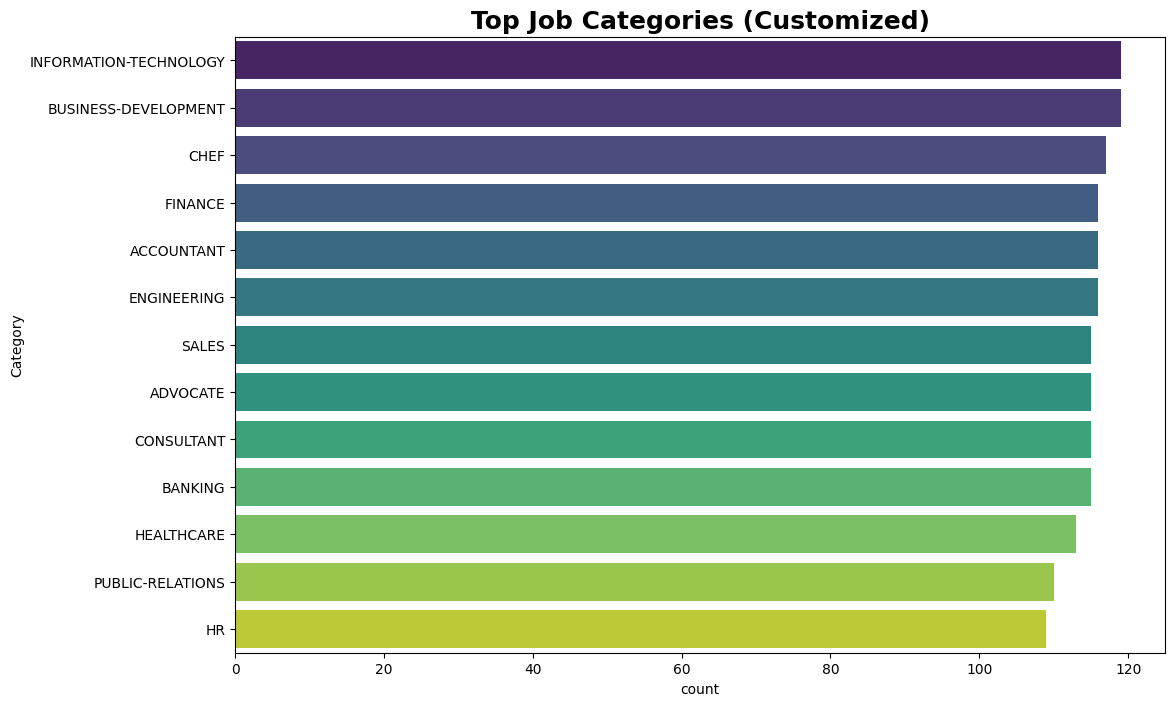

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('Resume.csv')

top_15_categories = df['Category'].value_counts().nlargest(15).index
df = df[df['Category'].isin(top_15_categories)]

categories_to_remove = ['AVIATION', 'FITNESS']

df = df[~df['Category'].isin(categories_to_remove)]

plt.figure(figsize=(12, 8))

sns.countplot(y='Category', data=df, order=df['Category'].value_counts().index, palette='viridis')
plt.title('Top Job Categories (Customized)', fontsize=18, weight='bold')
plt.show()

In [ ]:
# Domain

import pandas as pd
domain_list = df['Category'].unique()

overview_df = pd.DataFrame(domain_list, columns=['Domain Category'])

overview_df.index = overview_df.index + 1
overview_df.index.name = '#'

print("Overview of Available Job Domains:")
print(overview_df.to_string())

Overview of Available Job Domains:
           Domain Category
#                         
1                       HR
2   INFORMATION-TECHNOLOGY
3                 ADVOCATE
4     BUSINESS-DEVELOPMENT
5               HEALTHCARE
6                    SALES
7               CONSULTANT
8                     CHEF
9                  FINANCE
10             ENGINEERING
11              ACCOUNTANT
12        PUBLIC-RELATIONS
13                 BANKING


In [ ]:
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [ ]:

import pandas as pd
import numpy as np
import re
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from sklearn.metrics import accuracy_score, classification_report


# --- Data Loading and Preprocessing ---
df = pd.read_csv('Resume.csv', usecols=['Resume_str', 'Category'])
df = df.dropna()

VALID_CATEGORIES = [
    'ACCOUNTANT', 'BANKING', 'BUSINESS-DEVELOPMENT', 'CHEF',
    'CONSTRUCTION', 'CONSULTANT', 'DESIGNER', 'DIGITAL-MEDIA', 'ENGINEERING',
    'FINANCE', 'HEALTHCARE', 'HR', 'INFORMATION-TECHNOLOGY',
    'PUBLIC-RELATIONS', 'SALES'
]

df = df[df['Category'].isin(VALID_CATEGORIES)].copy()
print(f"Filtered to {len(df)} rows with valid categories.")


def clean_text_for_bert(text):
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

df['cleaned_resume'] = df['Resume_str'].apply(clean_text_for_bert)

le = LabelEncoder()
df.loc[:, 'Category_Encoded'] = le.fit_transform(df['Category'])


X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned_resume'],
    df['Category_Encoded'],
    test_size=0.2,
    random_state=42,
    stratify=df['Category_Encoded']
)

# --- Tokenization ---
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize_data(texts):
    return tokenizer(
        texts.tolist(), padding=True, truncation=True,
        max_length=512, return_tensors='pt'
    )

train_encodings = tokenize_data(X_train)
test_encodings = tokenize_data(X_test)

# --- Create Datasets and Dataloaders ---
train_dataset = TensorDataset(train_encodings['input_ids'], train_encodings['attention_mask'], torch.tensor(y_train.values))
test_dataset = TensorDataset(test_encodings['input_ids'], test_encodings['attention_mask'], torch.tensor(y_test.values))

batch_size = 8
train_loader = DataLoader(train_dataset, sampler=RandomSampler(train_dataset), batch_size=batch_size)
test_loader = DataLoader(test_dataset, sampler=SequentialSampler(test_dataset), batch_size=batch_size)

# --- Model Initialization ---
model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=len(le.classes_)
)

optimizer = AdamW(model.parameters(), lr=5e-5)

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

model.to(device)
print(f"Using device: {device}")


# --- Training Loop ---
def train_model(epochs=3):
    model.train()
    for epoch in range(epochs):
        print(f"Epoch {epoch + 1}/{epochs}")
        for batch in train_loader:
            batch = [r.to(device) for r in batch]
            input_ids, attention_mask, labels = batch
            model.zero_grad()
            outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            loss.backward()
            optimizer.step()

print("Starting model training...")
train_model(epochs=3)
print("Model training complete.")



Filtered to 1689 rows with valid categories.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Using device: cuda
Starting model training...
Epoch 1/3
Epoch 2/3
Epoch 3/3
Model training complete.


In [ ]:
import torch
from sklearn.metrics import accuracy_score, classification_report

model.eval()

predictions, true_labels = [], []

with torch.no_grad():
    for batch in test_loader:
        batch = [t.to(device) for t in batch]
        input_ids, attention_mask, labels = batch

        outputs = model(input_ids, attention_mask=attention_mask)
        logits = outputs.logits

        predictions.extend(torch.argmax(logits, dim=1).tolist())
        true_labels.extend(labels.tolist())

accuracy = accuracy_score(true_labels, predictions)
print(f"BERT Model Accuracy: {accuracy * 100:.2f}%\n")

# Get the unique labels from the union of true labels and predictions
unique_labels = sorted(list(set(true_labels) | set(predictions)))

# Get the corresponding names for these labels from the label encoder
target_names_for_report = le.inverse_transform(unique_labels)

# Generate the report
report = classification_report(
    true_labels,
    predictions,
    labels=unique_labels,
    target_names=target_names_for_report,
    zero_division=0
)
print("BERT Model Classification Report:\n")
print(report)

BERT Model Accuracy: 90.53%

BERT Model Classification Report:

                        precision    recall  f1-score   support

            ACCOUNTANT       1.00      0.87      0.93        23
               BANKING       0.67      0.87      0.75        23
  BUSINESS-DEVELOPMENT       0.96      0.96      0.96        24
                  CHEF       1.00      0.91      0.95        23
          CONSTRUCTION       0.78      0.95      0.86        22
            CONSULTANT       0.90      0.83      0.86        23
              DESIGNER       0.95      0.95      0.95        21
         DIGITAL-MEDIA       0.89      0.84      0.86        19
           ENGINEERING       0.92      1.00      0.96        23
               FINANCE       1.00      1.00      1.00        23
            HEALTHCARE       0.94      0.74      0.83        23
                    HR       1.00      1.00      1.00        22
INFORMATION-TECHNOLOGY       0.94      0.71      0.81        24
      PUBLIC-RELATIONS       0.84      

In [ ]:
import re

def get_experience_level(resume_text):
    """
    Analyzes resume text to determine the experience level based on keywords and year patterns.
    """
    text = resume_text.lower()

    # --- 1. Top-Priority Keyword Check ---
    # These keywords are strong indicators of a specific level.
    if re.search(r'executive|vp|director|c-level|cto|ceo', text):
        return "Executive/Leadership (10+ years)"

    if re.search(r'entry-level|entry level|recent graduate|intern', text):
        return "Entry Level (0-2 years)"

    # --- 2. Numeric Year-Based Check ---
    # Looks for patterns like "8 years", "5+ years", "10 years experience"
    # We look for numbers between 1 and 25.
    pattern = r'(\b(?:[1-9]|1[0-9]|2[0-5])\b)\s*(?:\+|plus)?\s*year[s\']?'

    matches = re.findall(pattern, text)

    if matches:
        # Find the highest number of years mentioned
        try:
            years_list = [int(m) for m in matches]
            max_years = max(years_list)

            if max_years >= 10:
                return "Executive/Leadership (10+ years)"
            if 6 <= max_years < 10:
                return "Senior Level (6-10 years)"
            if 3 <= max_years < 6:
                return "Mid-Level (3-5 years)"
            if max_years < 3:
                return "Entry Level (0-2 years)"

        except Exception as e:
            # In case of any conversion error, just skip to the next method
            pass

    # --- 3. Fallback Keyword Check ---
    # If no numbers are found, check for other common titles.
    if re.search(r'senior|sr\.|lead|manager|principal', text):
        return "Senior Level (6-10 years)"

    if re.search(r'junior|jr\.', text):
        return "Entry Level (0-2 years)"

    # --- 4. Default ---
    # If no other indicators are found, default to Mid-Level
    # (or Entry-Level, depending on assumption)
    return "Mid-Level (3-5 years)"

# --- Let's test our new function ---
print("--- Testing the Experience Level Classifier ---")

resume_1 = "Senior software engineer with 8 years of experience in Python."
resume_2 = "A recent graduate seeking an entry-level position in marketing."
resume_3 = "Visionary executive with 15+ years in global finance operations."
resume_4 = "Data analyst with 4 years' experience in SQL and Tableau."
resume_5 = "A junior developer on the front-end team."
resume_6 = "A highly motivated manager and team lead."

print(f"Resume 1: '{get_experience_level(resume_1)}'")
print(f"Resume 2: '{get_experience_level(resume_2)}'")
print(f"Resume 3: '{get_experience_level(resume_3)}'")
print(f"Resume 4: '{get_experience_level(resume_4)}'")
print(f"Resume 5: '{get_experience_level(resume_5)}'")
print(f"Resume 6: '{get_experience_level(resume_6)}'")


--- Testing the Experience Level Classifier ---
Resume 1: 'Senior Level (6-10 years)'
Resume 2: 'Entry Level (0-2 years)'
Resume 3: 'Executive/Leadership (10+ years)'
Resume 4: 'Mid-Level (3-5 years)'
Resume 5: 'Entry Level (0-2 years)'
Resume 6: 'Senior Level (6-10 years)'


In [ ]:
import re

def get_secondary_industry(resume_text, primary_industry):
    """
    Analyzes resume text to determine the secondary industry (e.g., sub-field)
    based on the primary industry and keywords.
    """
    text = resume_text.lower()

    # We use a scoring system to find the "best fit"
    scores = {}
    keywords = {}

    # --- 1. Rules for INFORMATION-TECHNOLOGY ---
    if primary_industry == "INFORMATION-TECHNOLOGY":
        scores = {
            "Software Development": 0, "Data Science/Analytics": 0, "Cybersecurity": 0,
            "DevOps/Infrastructure": 0, "Product Management": 0
        }
        keywords = {
            "Software Development": ['java', 'python', 'c#', '.net', 'javascript', 'react', 'angular',
                                     'node.js', 'software engineer', 'developer', 'coding', 'programming'],
            "Data Science/Analytics": ['sql', 'tableau', 'power bi', 'pandas', 'numpy', 'scipy', 'machine learning',
                                       'data analyst', 'data scientist', 'analytics', 'visualization', 'r', 'stata'],
            "Cybersecurity": ['cybersecurity', 'security', 'firewall', 'penetration testing', 'iam', 'siem',
                              'infosec', 'encryption', 'cissp', 'malware analysis'],
            "DevOps/Infrastructure": ['aws', 'azure', 'gcp', 'docker', 'kubernetes', 'terraform', 'ansible',
                                      'devops', 'ci/cd', 'infrastructure', 'sysadmin', 'network'],
            "Product Management": ['product manager', 'product owner', 'agile', 'scrum', 'user stories',
                                   'product roadmap', 'market research', 'ux', 'ui']
        }

    # --- 2. Rules for FINANCE ---
    elif primary_industry == "FINANCE":
        scores = {"Investment Banking": 0, "Corporate Finance": 0, "Quantitative Finance": 0}
        keywords = {
            "Investment Banking": ['investment banking', 'm&a', 'mergers', 'acquisitions', 'capital markets', 'due diligence'],
            "Corporate Finance": ['financial planning', 'fp&a', 'budgeting', 'forecasting', 'corporate finance'],
            "Quantitative Finance": ['quantitative', 'quant', 'stochastic', 'derivatives', 'financial modeling', 'c++']
        }

    # --- 3. Rules for ENGINEERING ---
    elif primary_industry == "ENGINEERING":
        scores = {"Mechanical": 0, "Civil": 0, "Electrical": 0, "Software": 0}
        keywords = {
            "Mechanical": ['mechanical', 'solidworks', 'autocad', 'fea', 'thermodynamics', 'hvac'],
            "Civil": ['civil engineer', 'structural', 'geotechnical', 'autocad civil 3d', 'concrete', 'steel'],
            "Electrical": ['electrical', 'pcb', 'circuit', 'power systems', 'vlsi', 'matlab'],
            "Software": ['software engineer', 'developer', 'coding', 'programming', 'c++', 'python', 'java']
        }

    # --- 4. Rules for ACCOUNTANT ---
    elif primary_industry == "ACCOUNTANT":
        scores = {"Tax": 0, "Audit": 0, "General Ledger": 0}
        keywords = {
            "Tax": ['tax', 'taxation', 'tax compliance', 'tax preparation', 'irs'],
            "Audit": ['audit', 'auditor', 'internal audit', 'sox', 'gaap', 'ifrs'],
            "General Ledger": ['general ledger', 'bookkeeping', 'accounts payable', 'accounts receivable', 'reconciliation']
        }

    # --- 5. Rules for BANKING ---
    elif primary_industry == "BANKING":
        scores = {"Retail Banking": 0, "Commercial Banking": 0, "Risk/Compliance": 0}
        keywords = {
            "Retail Banking": ['retail banking', 'branch manager', 'personal banker', 'teller', 'mortgage', 'loans'],
            "Commercial Banking": ['commercial banking', 'business banking', 'underwriting', 'credit analyst'],
            "Risk/Compliance": ['risk management', 'compliance', 'aml', 'kyc', 'anti-money laundering', 'bds']
        }

    # --- 6. Rules for BUSINESS-DEVELOPMENT ---
    elif primary_industry == "BUSINESS-DEVELOPMENT":
        scores = {"Lead Generation": 0, "Strategic Partnerships": 0, "Market Analysis": 0}
        keywords = {
            "Lead Generation": ['lead generation', 'cold calling', 'salesforce', 'crm', 'prospecting'],
            "Strategic Partnerships": ['partnerships', 'strategic alliances', 'channel partners', 'business development'],
            "Market Analysis": ['market research', 'market analysis', 'new markets', 'competitor analysis']
        }

    # --- 7. Rules for CHEF ---
    elif primary_industry == "CHEF":
        scores = {"Pastry": 0, "Kitchen Management": 0, "Cuisine Specialty": 0}
        keywords = {
            "Pastry": ['pastry', 'baking', 'baker', 'patisserie', 'dessert'],
            "Kitchen Management": ['executive chef', 'sous chef', 'kitchen manager', 'inventory', 'cost control', 'staff training'],
            "Cuisine Specialty": ['italian', 'french', 'asian', 'fusion', 'fine dining', 'catering']
        }

    # --- 8. Rules for CONSTRUCTION ---
    elif primary_industry == "CONSTRUCTION":
        scores = {"Project Management": 0, "Site Supervision": 0, "Estimating": 0}
        keywords = {
            "Project Management": ['project manager', 'pmp', 'construction management', 'scheduling', 'budgeting'],
            "Site Supervision": ['site supervisor', 'superintendent', 'foreman', 'safety', 'osha'],
            "Estimating": ['estimator', 'cost estimation', 'bidding', 'take-offs']
        }

    # --- 9. Rules for CONSULTANT ---
    elif primary_industry == "CONSULTANT":
        scores = {"Management": 0, "Technical": 0, "Strategy": 0}
        keywords = {
            "Management": ['management consultant', 'business process', 'optimization', 'operations', 'change management'],
            "Technical": ['it consultant', 'technical consultant', 'sap', 'oracle', 'salesforce', 'implementation'],
            "Strategy": ['strategy consultant', 'mckinsey', 'bcg', 'bain', 'corporate strategy', 'market entry']
        }

    # --- 10. Rules for DESIGNER ---
    elif primary_industry == "DESIGNER":
        scores = {"Graphic/Visual": 0, "UX/UI": 0, "Industrial/Product": 0}
        keywords = {
            "Graphic/Visual": ['graphic design', 'photoshop', 'illustrator', 'indesign', 'typography', 'branding'],
            "UX/UI": ['ux', 'ui', 'user experience', 'user interface', 'figma', 'sketch', 'wireframing', 'prototyping'],
            "Industrial/Product": ['industrial design', 'product design', 'solidworks', 'rhino', '3d modeling', 'manufacturing']
        }

    # --- 11. Rules for DIGITAL-MEDIA ---
    elif primary_industry == "DIGITAL-MEDIA":
        scores = {"SEO/SEM": 0, "Social Media": 0, "Content Creation": 0}
        keywords = {
            "SEO/SEM": ['seo', 'sem', 'search engine optimization', 'google analytics', 'ppc', 'adwords'],
            "Social Media": ['social media', 'community manager', 'facebook', 'instagram', 'twitter', 'content strategy'],
            "Content Creation": ['content creator', 'copywriting', 'video production', 'blogging', 'editing']
        }

    # --- 12. Rules for HEALTHCARE ---
    elif primary_industry == "HEALTHCARE":
        scores = {"Clinical": 0, "Administration": 0, "Research/Pharma": 0}
        keywords = {
            "Clinical": ['nurse', 'rn', 'doctor', 'physician', 'patient care', 'lpn', 'clinical', 'medical assistant'],
            "Administration": ['healthcare administration', 'hospital administrator', 'patient records', 'hipaa', 'medical billing'],
            "Research/Pharma": ['pharmaceutical', 'clinical research', 'biotech', 'fda', 'lab', 'scientist']
        }

    # --- 13. Rules for HR ---
    elif primary_industry == "HR":
        scores = {"Recruitment": 0, "Compensation/Benefits": 0, "Generalist": 0}
        keywords = {
            "Recruitment": ['recruiter', 'recruiting', 'talent acquisition', 'sourcing', 'ats', 'interviewing'],
            "Compensation/Benefits": ['compensation', 'benefits', 'payroll', 'comp & ben', 'hris'],
            "Generalist": ['hr generalist', 'hrbp', 'human resources business partner', 'employee relations', 'onboarding']
        }

    # --- 14. Rules for PUBLIC-RELATIONS ---
    elif primary_industry == "PUBLIC-RELATIONS":
        scores = {"Media Relations": 0, "Corporate Communications": 0, "Event Management": 0}
        keywords = {
            "Media Relations": ['media relations', 'press release', 'public relations', 'pr', 'pitching', 'media outreach'],
            "Corporate Communications": ['corporate communications', 'internal communications', 'employee communications'],
            "Event Management": ['event management', 'event planning', 'trade show', 'logistics']
        }

    # --- 15. Rules for SALES ---
    elif primary_industry == "SALES":
        scores = {"Tech Sales": 0, "B2B": 0, "Account Management": 0}
        keywords = {
            "Tech Sales": ['saas', 'software sales', 'tech sales', 'solution architect', 'pre-sales'],
            "B2B": ['b2b', 'business-to-business', 'enterprise sales', 'salesforce', 'crm'],
            "Account Management": ['account manager', 'key account', 'customer success', 'relationship manager']
        }

    else:
        # If the primary industry has no sub-rules (like FITNESS), return None
        return None

    # --- Calculate scores ---
    for category, klist in keywords.items():
        for keyword in klist:
            if re.search(r'\b' + re.escape(keyword) + r'\b', text):
                scores[category] += 1

    # Find the category with the highest score
    best_category = max(scores, key=scores.get)

    # Only return a category if it has a minimum score
    if scores[best_category] > 0: # We can set this to > 1 for higher confidence
        return best_category
    else:
        # If no keywords matched, return a general label
        return f"General {primary_industry}"

# --- Let's test our new function ---
print("--- Testing the Secondary Industry Classifier ---")

# Test IT resumes
resume_it_1 = "Senior Java Developer with 8 years of experience in programming, coding, and agile."
resume_it_2 = "Data Scientist skilled in machine learning, python, pandas, and SQL. Built several models."
# Test Finance resume
resume_fin_1 = "Analyst with 3 years in corporate finance, focused on budgeting and FP&A."
# Test Engineering resume
resume_eng_1 = "Mechanical Engineer with experience in SolidWorks and thermodynamics."
# Test HR resume
resume_hr_1 = "Talent acquisition specialist focused on sourcing and interviewing."
# Test Designer resume
resume_des_1 = "Senior UX/UI designer, focused on Figma and wireframing."
# Test Sales resume
resume_sales_1 = "Enterprise sales for a major SaaS company."

print(f"Resume (IT 1):   '{get_secondary_industry(resume_it_1, 'INFORMATION-TECHNOLOGY')}'")
print(f"Resume (IT 2):   '{get_secondary_industry(resume_it_2, 'INFORMATION-TECHNOLOGY')}'")
print(f"Resume (Fin 1):  '{get_secondary_industry(resume_fin_1, 'FINANCE')}'")
print(f"Resume (Eng 1):  '{get_secondary_industry(resume_eng_1, 'ENGINEERING')}'")
print(f"Resume (HR 1):   '{get_secondary_industry(resume_hr_1, 'HR')}'")
print(f"Resume (Des 1):  '{get_secondary_industry(resume_des_1, 'DESIGNER')}'")
print(f"Resume (Sales 1):'{get_secondary_industry(resume_sales_1, 'SALES')}'")



--- Testing the Secondary Industry Classifier ---
Resume (IT 1):   'Software Development'
Resume (IT 2):   'Data Science/Analytics'
Resume (Fin 1):  'Corporate Finance'
Resume (Eng 1):  'Mechanical'
Resume (HR 1):   'Recruitment'
Resume (Des 1):  'UX/UI'
Resume (Sales 1):'Tech Sales'


In [ ]:
import re

# --- Module 4: Work Type Classifier ---
def get_work_type(resume_text):
    """Analyzes resume text for work type (Remote, Hybrid, On-site)."""
    text = resume_text.lower()

    # Use \b for whole word matching
    has_remote = re.search(r'\bremote\b|work from home|wfh', text)
    has_hybrid = re.search(r'\bhybrid\b', text)
    has_onsite = re.search(r'\bon-site\b|on site|in-office', text)

    if has_hybrid:
        return "Hybrid"
    if has_remote and not has_onsite: # Look for 'remote' but not in a phrase like 'remote or on-site'
        return "Remote"
    if has_onsite and not has_remote:
        return "On-site"

    # If both or neither are mentioned, it's ambiguous. We can return a default.
    # 'On-site' is a safe default for most traditional resumes.
    return "On-site (Assumed)"

# --- Module 5: Employment Type Classifier ---
def get_employment_type(resume_text):
    """Analyzes resume text for employment type (Full-time, Contract, etc.)."""
    text = resume_text.lower()

    if re.search(r'\bintern\b|\binternship\b', text):
        return "Internship"
    if re.search(r'\bcontract\b|\bcontractor\b|\bfreelance\b', text):
        return "Contract"
    if re.search(r'part-time\b|part time', text):
        return "Part-time"

    # 'Full-time' is often unstated, so it's a good default.
    return "Full-time"

# --- Module 6: Skill-Based Role Classifier ---
def get_skill_role(resume_text, primary_industry):
    """Analyzes resume text for the general role type (Technical, Management, etc.)."""
    text = resume_text.lower()

    # --- 1. Management Role ---
    # High-confidence keywords for leadership
    if re.search(r'\bmanager\b|\bdirector\b|\blead\b|team lead|managing|supervising|vp of', text):
        return "Management Role"

    # --- 2. Technical Role ---
    # Check if the industry itself is technical OR if it contains technical keywords
    technical_industries = ['INFORMATION-TECHNOLOGY', 'ENGINEERING', 'ACCOUNTANT', 'FINANCE', 'BANKING']
    technical_keywords = ['python', 'java', 'sql', 'aws', 'autocad', 'solidworks', 'matlab', 'technical']
    if primary_industry in technical_industries:
        return "Technical Role"
    for keyword in technical_keywords:
        if re.search(r'\b' + re.escape(keyword) + r'\b', text):
            return "Technical Role"

    # --- 3. Creative Role ---
    creative_industries = ['DESIGNER', 'DIGITAL-MEDIA', 'ARTS', 'PUBLIC-RELATIONS']
    creative_keywords = ['design', 'photoshop', 'figma', 'creative', 'writing', 'content', 'visual']
    if primary_industry in creative_industries:
        return "Creative Role"
    for keyword in creative_keywords:
        if re.search(r'\b' + re.escape(keyword) + r'\b', text):
            return "Creative Role"

    # --- 4. Analytical Role ---
    analytical_keywords = ['analyst', 'analysis', 'reporting', 'research', 'analytics', 'data']
    for keyword in analytical_keywords:
        if re.search(r'\b' + re.escape(keyword) + r'\b', text):
            return "Analytical Role"

    # --- 5. Other (e.g., Service, Physical) ---
    service_industries = ['CHEF', 'HEALTHCARE', 'FITNESS', 'SALES', 'HR']
    if primary_industry in service_industries:
        return "Service/Operational Role"

    return "General Role"

# --- Let's test our new functions ---
print("--- Testing the Work Type & Role Classifiers ---")

test_resume = """
Senior Software Engineering Manager with 10 years of experience, specializing in Python and AWS.
I am looking for a full-time, hybrid role. My work involves managing a team of 10,
but I also do a lot of data analysis and reporting.
"""
primary_industry_test = "INFORMATION-TECHNOLOGY" # From our BERT model

print(f"Work Type:      '{get_work_type(test_resume)}'")
print(f"Employment Type:  '{get_employment_type(test_resume)}'")
print(f"Skill Role:       '{get_skill_role(test_resume, primary_industry_test)}'")


--- Testing the Work Type & Role Classifiers ---
Work Type:      'Hybrid'
Employment Type:  'Full-time'
Skill Role:       'Management Role'


In [ ]:
import pandas as pd
import torch
from tqdm.auto import tqdm
import re

print("Loading all classifier modules...")

def predict_primary_industry(text, model, tokenizer, label_encoder, device):
    model.eval()
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    prediction = torch.argmax(logits, dim=-1).cpu().numpy()[0]
    return label_encoder.inverse_transform([prediction])[0]

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+\s*', ' ', text)
    text = re.sub(r'rt|cc', ' ', text)
    text = re.sub(r'#\S+', '', text)
    text = re.sub(r'@\S+', '  ', text)
    text = re.sub(r'[%s]' % re.escape("""!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~"""), ' ', text)
    text = re.sub(r'[^\x00-\x7f]', r' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

print("Loading original clean data...")
try:
    df_raw = pd.read_csv('Resume.csv', usecols=['Resume_str', 'Category'])
except FileNotFoundError:
    print("ERROR: 'Resume.csv' not found. Please upload it again.")
    raise

VALID_CATEGORIES = [
    'ACCOUNTANT', 'BANKING', 'BUSINESS-DEVELOPMENT', 'CHEF', 'CONSTRUCTION',
    'CONSULTANT', 'DESIGNER', 'DIGITAL-MEDIA', 'ENGINEERING', 'FINANCE',
    'FITNESS', 'HEALTHCARE', 'HR', 'INFORMATION-TECHNOLOGY', 'PUBLIC-RELATIONS', 'SALES'
]

df_clean = df_raw[df_raw['Category'].isin(VALID_CATEGORIES)].copy()
df_clean['cleaned_resume'] = df_clean['Resume_str'].apply(clean_text)
df_clean = df_clean.dropna(subset=['cleaned_resume'])
df_clean = df_clean.drop_duplicates(subset=['cleaned_resume'])
print(f"Loaded {len(df_clean)} clean resumes.")

print("Starting enrichment pipeline... This may take a few minutes.")

primary_industries = []
secondary_industries = []
experience_levels = []
work_types = []
employment_types = []
skill_roles = []

for _, row in tqdm(df_clean.iterrows(), total=len(df_clean)):
    resume_text = row['cleaned_resume']

    primary_industry = predict_primary_industry(resume_text, model, tokenizer, le, device)
    primary_industries.append(primary_industry)

    experience_levels.append(get_experience_level(resume_text))

    secondary_industries.append(get_secondary_industry(resume_text, primary_industry))

    work_types.append(get_work_type(resume_text))

    employment_types.append(get_employment_type(resume_text))

    skill_roles.append(get_skill_role(resume_text, primary_industry))

print("Enrichment complete.")

print("Saving enriched dataset...")
df_enriched = df_clean.copy()

df_enriched['primary_industry_pred'] = primary_industries
df_enriched['secondary_industry'] = secondary_industries
df_enriched['experience_level'] = experience_levels
df_enriched['work_type'] = work_types
df_enriched['employment_type'] = employment_types
df_enriched['skill_role'] = skill_roles

final_columns = [
    'primary_industry_pred',
    'secondary_industry',
    'experience_level',
    'skill_role',
    'work_type',
    'employment_type',
    'Resume_str',
    'cleaned_resume',
    'Category'
]
df_enriched = df_enriched[final_columns]

output_filename = 'enriched_resumes.csv'
df_enriched.to_csv(output_filename, index=False)

print(f"Successfully created '{output_filename}'!")
print("\n--- Enriched Dataset Preview ---")
print(df_enriched.head())



<>:26: SyntaxWarning: invalid escape sequence '\]'
<>:26: SyntaxWarning: invalid escape sequence '\]'
/tmp/ipython-input-1455880845.py:26: SyntaxWarning: invalid escape sequence '\]'
  text = re.sub(r'[%s]' % re.escape("""!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~"""), ' ', text)


Loading all classifier modules...
Loading original clean data...
Loaded 1805 clean resumes.
Starting enrichment pipeline... This may take a few minutes.


  0%|          | 0/1805 [00:00<?, ?it/s]

Enrichment complete.
Saving enriched dataset...
Successfully created 'enriched_resumes.csv'!

--- Enriched Dataset Preview ---
  primary_industry_pred     secondary_industry  \
0                    HR  Compensation/Benefits   
1                    HR  Compensation/Benefits   
2                    HR  Compensation/Benefits   
3                    HR  Compensation/Benefits   
4                    HR  Compensation/Benefits   

                   experience_level                skill_role  \
0  Executive/Leadership (10+ years)           Management Role   
1  Executive/Leadership (10+ years)           Management Role   
2  Executive/Leadership (10+ years)           Management Role   
3           Entry Level (0-2 years)  Service/Operational Role   
4  Executive/Leadership (10+ years)           Management Role   

           work_type employment_type  \
0  On-site (Assumed)       Full-time   
1  On-site (Assumed)       Full-time   
2  On-site (Assumed)        Contract   
3  On-site (Assumed) 

In [ ]:
import pandas as pd

def find_matching_candidates(
    primary_industry=None,
    secondary_industry=None,
    experience_level=None,
    skill_role=None,
    work_type=None,
    employment_type=None,
    keyword=None,
    export_filename='search_results.csv'
):

    try:
        df = pd.read_csv('enriched_resumes.csv')
    except FileNotFoundError:
        print("ERROR: 'enriched_resumes.csv' not found.")
        print("Please re-run Cell 6 (the enrichment pipeline) to create it.")
        return

    results = df.copy()

    if primary_industry:
        results = results[results['primary_industry_pred'].str.contains(primary_industry, case=False, na=False)]

    if secondary_industry:
        results = results[results['secondary_industry'].str.contains(secondary_industry, case=False, na=False)]

    if experience_level:
        results = results[results['experience_level'].str.contains(experience_level, case=False, na=False)]

    if skill_role:
        results = results[results['skill_role'].str.contains(skill_role, case=False, na=False)]

    if work_type:
        results = results[results['work_type'].str.contains(work_type, case=False, na=False)]

    if employment_type:
        results = results[results['employment_type'].str.contains(employment_type, case=False, na=False)]

    if keyword:
        keyword = keyword.lower()
        results = results[results['cleaned_resume'].str.contains(keyword, case=False, na=False)]

    if results.empty:
        print("No candidates found matching your criteria.")
        return

    try:
        results.to_csv(export_filename, index=False)
        print(f"Success! Found {len(results)} matching candidates.")
        print(f"Results exported to '{export_filename}'.")

        print("\n--- Preview of Results ---")
        print(results.head())

    except Exception as e:
        print(f"An error occurred while exporting the file: {e}")

    return results

print("Recruiter Search Tool is ready.")
print("Call the 'find_matching_candidates()' function to start a search.")


Recruiter Search Tool is ready.
Call the 'find_matching_candidates()' function to start a search.


In [ ]:
print("--- Search 1: Senior Civil Engineers ---")
find_matching_candidates(
    primary_industry="ENGINEERING",
    secondary_industry="Civil",
    experience_level="Senior Level",
    export_filename="senior_civil_engineers.csv"
)

print("\n--- Search 2: Healthcare 'Management' roles ---")
find_matching_candidates(
    primary_industry="HEALTHCARE",
    skill_role="Management Role",
    export_filename="healthcare_managers.csv"
)

print("\n--- Search 3: 'Remote' roles in 'Tech Sales' ---")
find_matching_candidates(
    secondary_industry="Tech Sales",
    work_type="Remote",
    export_filename="remote_tech_sales.csv"
)

print("\n--- Search 4: HR specialists in 'Recruitment' who mention 'onboarding' ---")
find_matching_candidates(
    primary_industry="HR",
    secondary_industry="Recruitment",
    keyword="onboarding",
    export_filename="hr_recruitment_onboarding.csv"
)

print("\n--- Search 5: All 'Part-time' or 'Contract' 'Creative Roles' ---")
find_matching_candidates(
    skill_role="Creative Role",
    employment_type="Part-time|Contract",
    export_filename="creative_gigs.csv"
)

print("\n--- Search 6: Mid-Level 'Analytical' roles in 'BANKING' ---")
find_matching_candidates(
    primary_industry="BANKING",
    skill_role="Analytical Role",
    experience_level="Mid-Level",
    export_filename="mid_level_banking_analysts.csv"
)

print("\n--- Search 7: Entry Level 'CONSULTANT' resumes ---")
find_matching_candidates(
    primary_industry="CONSULTANT",
    experience_level="Entry Level",
    export_filename="entry_level_consultants.csv"
)


--- Search 1: Senior Civil Engineers ---
No candidates found matching your criteria.

--- Search 2: Healthcare 'Management' roles ---
Success! Found 100 matching candidates.
Results exported to 'healthcare_managers.csv'.

--- Preview of Results ---
    primary_industry_pred  secondary_industry  \
453            HEALTHCARE            Clinical   
454            HEALTHCARE            Clinical   
455            HEALTHCARE  General HEALTHCARE   
456            HEALTHCARE  General HEALTHCARE   
457            HEALTHCARE            Clinical   

                     experience_level       skill_role          work_type  \
453  Executive/Leadership (10+ years)  Management Role             Remote   
454  Executive/Leadership (10+ years)  Management Role  On-site (Assumed)   
455           Entry Level (0-2 years)  Management Role  On-site (Assumed)   
456         Senior Level (6-10 years)  Management Role  On-site (Assumed)   
457  Executive/Leadership (10+ years)  Management Role             Remo

,primary_industry_pred,secondary_industry,experience_level,skill_role,work_type,employment_type,Resume_str,cleaned_resume,Category
799,CONSULTANT,Technical,Entry Level (0-2 years),Management Role,Remote,Full-time,IT CONSULTANT Summary ...,it consultant summary over seven years of soft...,CONSULTANT
804,CONSULTANT,Management,Entry Level (0-2 years),General Role,On-site (Assumed),Full-time,CONSULTANT Professional Sum...,consultant professional summary substance abus...,CONSULTANT
807,CONSULTANT,Technical,Entry Level (0-2 years),Management Role,On-site (Assumed),Internship,CONSULTANT Career Focus To o...,consultant career focus to obtain a position i...,CONSULTANT
808,CONSULTANT,Technical,Entry Level (0-2 years),Analytical Role,On-site (Assumed),Full-time,CONSULTANT Professional Profile...,consultant professional profile to obtain a ta...,CONSULTANT
809,CONSULTANT,General CONSULTANT,Entry Level (0-2 years),Management Role,On-site (Assumed),Full-time,CONSULTANT Summary Profe...,consultant summary professional dedicated hard...,CONSULTANT
816,CONSULTANT,Management,Entry Level (0-2 years),Management Role,On-site (Assumed),Internship,CONSULTANT Career Focus ...,consultant career focus analytical and results...,CONSULTANT
819,CONSULTANT,Technical,Entry Level (0-2 years),Management Role,On-site (Assumed),Full-time,CONSULTANT Summary Transitio...,consultant summary transition from an applicat...,CONSULTANT
821,CONSULTANT,Management,Entry Level (0-2 years),Technical Role,On-site (Assumed),Internship,CONSULTANT Professional Summa...,consultant professional summary health care ad...,CONSULTANT
827,CONSULTANT,Management,Entry Level (0-2 years),Management Role,On-site (Assumed),Full-time,IT CONSULTANT Professional Su...,it consultant professional summary highly qual...,CONSULTANT
834,CONSULTANT,General CONSULTANT,Entry Level (0-2 years),Management Role,On-site (Assumed),Full-time,CONSULTANT Summary Military ...,consultant summary military veteran and phd wi...,CONSULTANT
